# Quantum Teleblur

Quantum Teleblur morphs one image into another through qubit rotations.

## Setup

In [6]:
import getpass
import os

from moth_atlas import Atlas

if not os.environ.get("MOTH_API_KEY"):
    os.environ["MOTH_API_KEY"] = getpass.getpass("Atlas API key")

client = Atlas()  # reads MOTH_API_KEY

In [7]:
import base64
from IPython.display import HTML, display

def row(images, width=170):
    """Show {label: image bytes} side by side."""
    cells = "".join(f'<td align="center"><img src="data:image/png;base64,{base64.b64encode(data).decode()}" width="{width}"><br>{label}</td>'
                    for label, data in images.items())
    display(HTML(f"<table><tr>{cells}</tr></table>"))  # a table: GitHub's renderer strips inline styles

## Try it

Point `image1` (source) and `image2` (target) at your own images, or keep the samples beside this notebook.

telablur-v1 job e707a5a5 submitted
telablur-v1 job e707a5a5 completed (3s)


image1 (source),result,image2 (target)

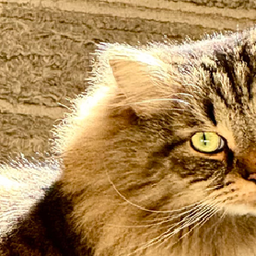
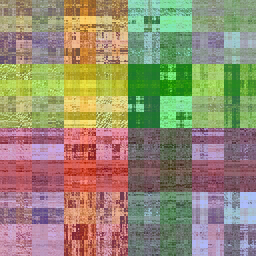
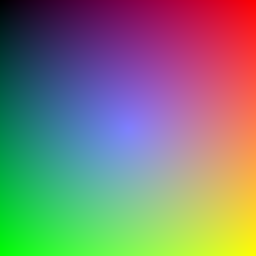

In [8]:
job = client.jobs.run(
    engine="telablur-v1",
    params={
        "strength": 0.5,
        "direction": "full",
    },
    files={
        "image1": "image1.png",
        "image2": "image2.png",
    },
)
row({"image1 (source)": open("image1.png", "rb").read(), "result": job.output_bytes(), "image2 (target)": open("image2.png", "rb").read()}, width=200)

## Parameters

What to expect from each:

- `strength` (0 to 1): from `image1` unchanged at 0 to the full effect at 1.
- `direction`: `full` rotates all pixel qubits; `vertical` and `horizontal` limit the blur to one axis.
- `size` and `downscale`: a region over the pixel budget is downscaled (`true`) or tiled (`false`).
- `mask` (input file): black keeps `image1`, white applies the full effect; without one, `image1`'s alpha channel is used. `mask_bin_size` and `mask_min_region` clean it up.

`image2` is resized to match `image1` if the sizes differ.

The engine's full definition:

In [9]:
client.engines.get("telablur-v1")  # its description, params, input and output files

**telablur-v1** · Quantum Teleblur · v1.3.0 · 1 credit per run

Morph one image into another through quantum rotation gates.

**Params**

| param | type | default | range | description |
|---|---|---|---|---|
| backend | string \| null | None |   | Device name for `emu`/`qpu` (e.g. `fez`, `marrakesh`, `garnet`). `emu` resolves it to the device's … |
| direction | 'full' \| 'vertical' \| 'horizontal' | 'full' |   | Which qubits receive the blur rotation, controlling the spatial direction of the blur effect: - `fu… |
| downscale | boolean | True |   | If True, oversized regions are downscaled before teleport and upscaled back. If False, oversized re… |
| execution_mode | 'sim' \| 'emu' \| 'qpu' \| 'local' | 'sim' |   | Where the quantum teleport runs, through moth_backbone: - `sim` - exact statevector simulation (def… |
| io | object \| null | None |   | Standard moth_backbone execution block: mode (sim \| emu \| qpu), provider (ibm \| iqm), backend, shot… |
| machine | string \| null | None |   | Platform shorthand for where to run, one key instead of execution_mode / provider / backend: `aer` … |
| mask_bin_size | number \| null | 4 | >= 0, <= 100 | Mask quantisation step as a percentage of 255 (0–100). Pixel values below this threshold are treate… |
| mask_min_region | integer \| null | 16 | >= 1 | Minimum mask region size in pixels. Connected components smaller than this are discarded after quan… |
| provider | 'aer' \| 'ibm' \| 'iqm' | 'aer' |   | Provider for `emu`/`qpu`: `ibm` or `iqm`. Ignored for `sim`/`local` (always aer). |
| shots | integer | 4096 | >= 1, <= 100000 | Measurements per circuit on `emu`/`qpu` - the teleport is estimated from them, so more shots = less… |
| size | integer | 1024 | >= 8, <= 1024 | Pixel budget per teleblur pass: a region up to `size × size` pixels is teleported in a single pass.… |
| store_results | boolean | True |   | Store every executed circuit (result, fidelity, calibration) through moth_backbone. |
| strength | number | 0.5 | >= 0, <= 1 | Strength of the teleportation effect, between 0.0 and 1.0 |

**Input files**

| slot | required | types | description |
|---|---|---|---|
| image1 | required | image/png, image/jpeg, image/webp, image/tiff, image/bmp | The source image. The teleblur effect morphs this image toward image2 through quantum rotation gate… |
| image2 | required | image/png, image/jpeg, image/webp, image/tiff, image/bmp | The target image. The teleblur effect morphs image1 toward this image. If the dimensions differ fro… |
| mask | optional | image/png, image/jpeg, image/webp, image/tiff, image/bmp | Optional mask controlling where the effect is applied, on a per-pixel basis. Each output pixel is a… |

**Returns files (job.outputs)**

| slot | types | description |
|---|---|---|
| result | image/png, image/jpeg, image/webp, image/tiff, image/bmp | The processed image. |

**Example**

```python
job = client.jobs.run(
    engine="telablur-v1",
    params={
        "direction": "full",
        "downscale": True,
        "execution_mode": "sim",
        "mask_bin_size": 4,
        "mask_min_region": 16,
        "provider": "aer",
        "shots": 4096,
        "size": 1024,
        "store_results": True,
        "strength": 0.5,
    },
    files={
        "image1": "image1.png",
        "image2": "image2.png",
    },
)
```

Full docs: `engine.description_md`

## How it works

Both images are encoded into one quantum state on $n+1$ qubits: $n$ qubits for the pixels and one selector qubit that marks which image each amplitude belongs to. Rotating the selector qubit blends the two images at the amplitude level.

## Experiments

Each experiment changes one parameter and keeps the others fixed, and runs one job per value.

### Strength

Strength of the teleportation effect, from `image1` unchanged at 0 to the full effect at 1.

strength=0.0
strength=0.25
strength=0.5
strength=0.75
strength=1.0


strength 0.0,strength 0.25,strength 0.5,strength 0.75,strength 1.0

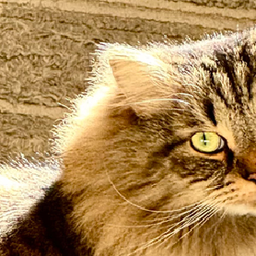
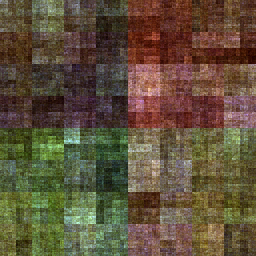
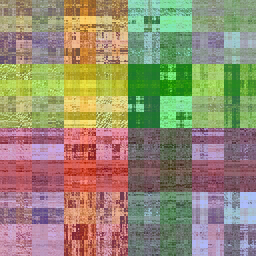
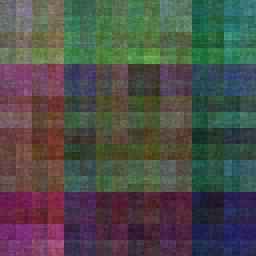
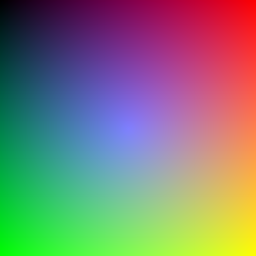

In [10]:
outputs = {}
for strength in (0.0, 0.25, 0.5, 0.75, 1.0):
    print(f"strength={strength}")
    job = client.jobs.run(engine="telablur-v1", params={"strength": strength}, files={"image1": "image1.png", "image2": "image2.png"}, quiet=True)
    outputs[f"strength {strength}"] = job.output_bytes()
row(outputs, width=160)

## Questions

**What if the two images are different sizes?**

image2 is resized to match image1.

**Why did my run fail?**

A run still going after 18,000 s is cancelled and the job ends failed. Mismatched mask sizes and masks with no non-zero pixels are rejected.